# Weights & Biases

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These tutorials use a CPU and the full original SIRDS bank. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `7a0813987944`](https://github.com/OJWatson/metis/tree/7a081398794492c82d92812b5801900f62f8639a).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Short uv setup cell shared by downloadable notebooks."""

import os
from pathlib import Path
import re
import shlex
import subprocess
import sys


def prepare_colab(revision):
    """Use the checkout's locked environment in Colab's active interpreter."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    if not (os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION")):
        print("Using your local METIS environment.")
        return
    # The source commit matches the results saved in this notebook.
    source = Path("/content/metis-tutorial")
    commands = f'''
set -euo pipefail
export PATH="$HOME/.local/bin:$PATH"
command -v uv >/dev/null || curl -LsSf https://astral.sh/uv/0.7.22/install.sh | sh
[ -d {source}/.git ] || git clone -q https://github.com/OJWatson/metis.git {source}
git -C {source} fetch -q origin {revision}
git -C {source} checkout -q --detach {revision}
uv sync --project {source} --python {shlex.quote(sys.executable)} --locked --inexact --no-dev --extra docs --no-editable
'''
    subprocess.run(
        ["bash", "-c", commands], check=True,
        env={**os.environ, "UV_PROJECT_ENVIRONMENT": sys.prefix, "UV_NO_MODIFY_PATH": "1"},
    )
    print("METIS is ready. If Colab reports a library-version conflict or asks for a restart, restart the session, then Run all.")


prepare_colab("7a081398794492c82d92812b5801900f62f8639a")


[Weights & Biases](https://wandb.ai) is a platform for managing sweeps and
tracking experiments. It lets you follow training progress and keep a record
of the settings and results from each run.

The walkthrough environment includes W&B. To track runs online, sign in:

```bash
uv run wandb login
```

If you installed only the library in your own project, add tracking with
`uv add "metis-surrogate[wandb] @ git+https://github.com/OJWatson/metis.git"`.

Enable tracking for the SIRDS training workflow with:

```bash
uv run metis train wandb.enabled=true wandb.project=sirds-surrogates
```

The same settings can go in your [Hydra configuration](https://ojwatson.github.io/metis/basics/hydra.html):

```yaml
wandb:
  enabled: true
  project: sirds-surrogates
  tags: [mlp, sirds]
```

For local tracking without an account, add `wandb.mode=offline` instead.

![A W&B dashboard from the original METIS training workflow. The installed package logs training loss, validation loss and final evaluation metrics.](https://ojwatson.github.io/metis/sweeping/images/example_wandb.png)

W&B collects the runs in a sweep together, lets you sort them by a metric such
as validation RMSE, and shows relationships between hyperparameters and model
performance:

![A W&B parameter-correlation view from the original METIS workflow.](https://ojwatson.github.io/metis/sweeping/images/parameter_correlation.png)

METIS logs configuration and scalar metrics. Your simulation tables and saved
model files stay local unless you upload them separately.

## Tracking from Python

The same tracker works with `Surrogate.fit`. This example runs in offline mode
so the notebook needs no account. Set `mode="online"` to see your runs in W&B
after signing in.

In [1]:
from dataclasses import asdict
from metis import load_example, Surrogate, TrainingConfig
from metis.tracking import WandbTracker

split = load_example().split(seed=42)
config = TrainingConfig(steps=500, eval_every=50)

with WandbTracker(
    project="sirds-surrogates",
    mode="offline",
    config={"model": "mlp", "training": asdict(config)},
) as tracking:
    surrogate = Surrogate("mlp").fit(
        split.train, split.validation, config=config,
        on_progress=tracking.log_training,
    )
    report = surrogate.evaluate(split.validation)
    tracking.log_evaluation(report, prefix="validation")

wandb: Tracking run with wandb version 0.30.0


wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /tmp/metis-docs-9pzv80hd/quarto/sweeping/wandb/offline-run-20261016_030940-tjnl89b4
wandb: View this run in the terminal with `wandb leet`


/home/runner/work/metis/metis/src/metis/surrogate.py:860: UserWarning: This bank overlaps training or tuning groups; these are not independent test results.
  return evaluate(self, dataset, **kwargs)
wandb: 
wandb: Run history:
wandb:                  learning_rate ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:                           step ▁▁▁▁▂▂▂▂▂▂▃▃▄▄▄▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇██
wandb:                     train_loss █▇▅▄▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:                 validation/mae ▁
wandb: validation/replicate_mean_rmse ▁
wandb:                validation/rmse ▁
wandb:                validation_loss █▃▃▂▂▂▁▁▁▁
wandb: 
wandb: Run summary:
wandb:                  learning_rate 0.001
wandb:                           step 500
wandb:                     train_loss 0.07893
wandb:                 validation/mae 29.44532
wandb: validation/replicate_mean_rmse 33.29012
wandb:                validation/rmse 45.12184
wandb:                validation_loss 0.08395
wandb: 


wandb: You can sync this run to the cloud by running:
wandb: wandb sync /tmp/metis-docs-9pzv80hd/quarto/sweeping/wandb/offline-run-20261016_030940-tjnl89b4


wandb: Find logs at: ./wandb/offline-run-20261016_030940-tjnl89b4/logs


The curve below shows the losses from this run, which are also recorded in
the local W&B log. Validation RMSE is measured in people; training and
validation losses use scaled outputs.

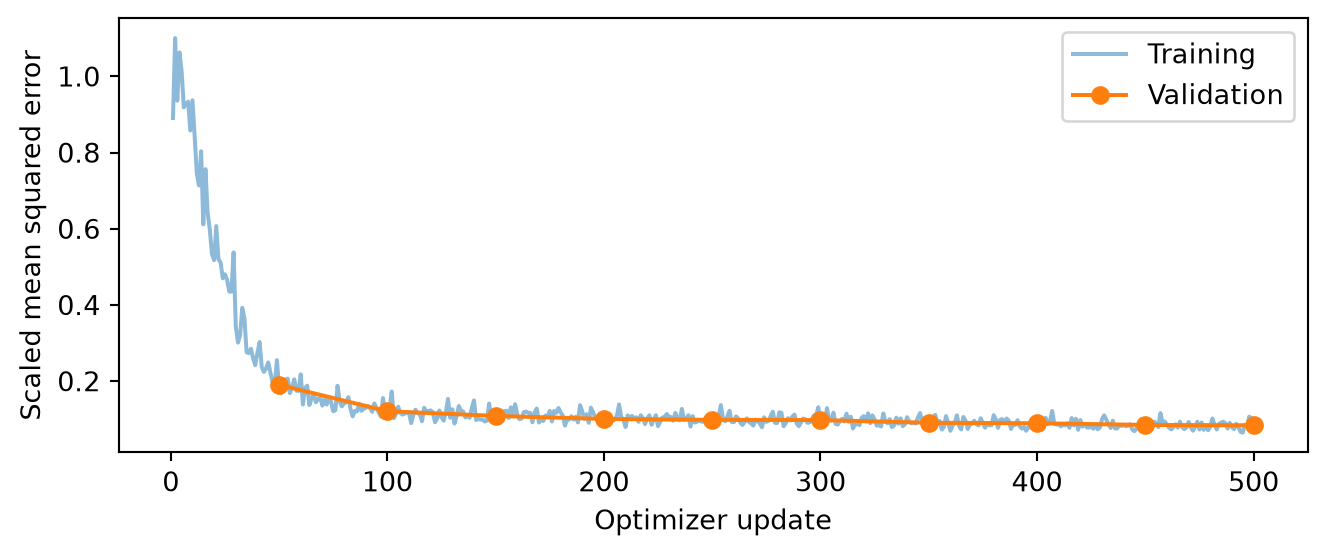

Validation RMSE: 45.12 people


In [2]:
#| fig-cap: "MLP tracked with W&B offline: 500 updates on 600 full-bank SIRDS training settings, with 200 separate validation settings."
import pandas as pd
import matplotlib.pyplot as plt

history = pd.DataFrame(surrogate.history)
validation = history.dropna(subset=["validation_loss"])
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(history.step, history.train_loss, alpha=0.5, label="Training")
ax.plot(validation.step, validation.validation_loss, "o-", label="Validation")
ax.set(xlabel="Optimizer update", ylabel="Scaled mean squared error")
ax.legend()
fig.tight_layout()
plt.show()
print(f"Validation RMSE: {report.metrics['rmse']:.2f} people")

*MLP tracked with W&B offline: 500 updates on 600 full-bank SIRDS training settings, with 200 separate validation settings.*

Next, [set up a sweep](https://ojwatson.github.io/metis/sweeping/sweep-config.html) to compare several training runs.